<a href="https://colab.research.google.com/github/nasy-sr/indobert-ruangguru-sentiment/blob/main/indobert_ruangguru_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CELL 1 — Install Library

In [ ]:
!pip uninstall transformers -y -q
!pip install transformers==4.41.0 datasets accelerate -q
!pip install imbalanced-learn -q
!pip install Sastrawi -q
!pip install wordcloud -q
!pip install scikit-learn matplotlib seaborn pandas numpy scipy -q

print("Semua library berhasil diinstall.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 14.2 MB/s eta 0:00:00
Semua library berhasil diinstall.


CELL 2 — Mount Google Drive dan Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_PATH = '/content/drive/MyDrive/Seminar_Nasional_2026_'
os.makedirs(DRIVE_PATH, exist_ok=True)
print(f"Drive terhubung. Folder: {DRIVE_PATH}")

Mounted at /content/drive
Drive terhubung. Folder: /content/drive/MyDrive/Seminar_Nasional_2026_


CELL 3 — Import Semua Library

In [ ]:
import os
import re
import pickle
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import scipy.stats as stats

from wordcloud import WordCloud
from collections import Counter
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import RandomOverSampler
from scipy.stats import wilcoxon, shapiro
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120

MODEL_NAME       = 'indobenchmark/indobert-base-p1'
NUM_LABELS       = 3
MAX_LEN          = 128
BATCH_SIZE       = 16
EPOCHS           = 3
LEARNING_RATE    = 2e-5
SAMPLE_PER_CLASS = 3000
COLORS           = {'positif': '#4CAF50', 'netral': '#2196F3', 'negatif': '#F44336'}
label_map        = {'negatif': 0, 'netral': 1, 'positif': 2}
label_map_inv    = {v: k for k, v in label_map.items()}
device           = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("Semua library berhasil diimport.")

Device: cuda
GPU: Tesla T4
Semua library berhasil diimport.


CELL 4 — Definisi Semua Class dan Fungsi

In [ ]:
# Dataset class
class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long)
        }


# Focal Loss
# Focal Loss adalah modifikasi dari cross-entropy yang memberikan
# bobot lebih besar pada sampel yang sulit diklasifikasikan.
# Parameter gamma mengontrol seberapa besar penekanan pada sampel sulit.
# Semakin besar gamma, semakin besar penekanan pada sampel sulit.
# Nilai gamma=2 adalah nilai yang umum digunakan di paper NLP.
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.gamma     = gamma
        self.alpha     = alpha
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt      = torch.exp(-ce_loss)
        focal   = (1 - pt) ** self.gamma * ce_loss

        if self.reduction == 'mean':
            return focal.mean()
        elif self.reduction == 'sum':
            return focal.sum()
        return focal


# Fungsi training standar
def train_one_epoch(model, loader, optimizer, scheduler, device):
    model.train()
    total_loss = 0
    for batch in loader:
        optimizer.zero_grad()
        output = model(
            input_ids      = batch['input_ids'].to(device),
            attention_mask = batch['attention_mask'].to(device),
            labels         = batch['labels'].to(device)
        )
        output.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += output.loss.item()
    return total_loss / len(loader)


# Fungsi training dengan weighted cross-entropy loss
def train_one_epoch_weighted(model, loader, optimizer, scheduler, device, class_weights):
    model.train()
    total_loss = 0
    loss_fn    = nn.CrossEntropyLoss(weight=class_weights)
    for batch in loader:
        optimizer.zero_grad()
        output = model(
            input_ids      = batch['input_ids'].to(device),
            attention_mask = batch['attention_mask'].to(device)
        )
        loss = loss_fn(output.logits, batch['labels'].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(loader)


# Fungsi training dengan focal loss
def train_one_epoch_focal(model, loader, optimizer, scheduler, device,
                          gamma=2.0, alpha=None):
    model.train()
    total_loss = 0
    loss_fn    = FocalLoss(gamma=gamma, alpha=alpha)
    for batch in loader:
        optimizer.zero_grad()
        output = model(
            input_ids      = batch['input_ids'].to(device),
            attention_mask = batch['attention_mask'].to(device)
        )
        loss = loss_fn(output.logits, batch['labels'].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(loader)


# Fungsi evaluasi
def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            output = model(
                input_ids      = batch['input_ids'].to(device),
                attention_mask = batch['attention_mask'].to(device)
            )
            preds = torch.argmax(output.logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['labels'].numpy())
    f1  = f1_score(all_labels, all_preds, average='weighted')
    acc = accuracy_score(all_labels, all_preds)
    rep = classification_report(
        all_labels, all_preds,
        target_names=['negatif', 'netral', 'positif'],
        output_dict=True
    )
    return f1, acc, all_preds, all_labels, rep


# Fungsi 10-Fold CV utama yang mendukung semua mode
def run_10fold_cv(texts, labels, tag='experiment',
                  mode='standard', class_weights=None,
                  focal_gamma=2.0, focal_alpha=None):
    """
    mode:
      'standard'   - cross-entropy biasa
      'weighted'   - weighted cross-entropy (cost-sensitive)
      'focal'      - focal loss
    """
    skf    = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    texts  = np.array(texts)
    labels = np.array(labels)

    fold_f1s    = []
    fold_accs   = []
    all_reports = []

    print(f"\n{'='*60}")
    print(f"10-FOLD CV | {tag.upper()} | mode: {mode}")
    print(f"{'='*60}")

    for fold, (train_idx, val_idx) in enumerate(skf.split(texts, labels), 1):
        print(f"\nFold {fold}/10")

        X_train = texts[train_idx].tolist()
        X_val   = texts[val_idx].tolist()
        y_train = labels[train_idx].tolist()
        y_val   = labels[val_idx].tolist()

        train_dl = DataLoader(
            ReviewDataset(X_train, y_train, tokenizer, MAX_LEN),
            batch_size=BATCH_SIZE, shuffle=True
        )
        val_dl = DataLoader(
            ReviewDataset(X_val, y_val, tokenizer, MAX_LEN),
            batch_size=BATCH_SIZE
        )

        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=NUM_LABELS
        ).to(device)

        optimizer   = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
        total_steps = len(train_dl) * EPOCHS
        scheduler   = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps   = int(0.1 * total_steps),
            num_training_steps = total_steps
        )

        for epoch in range(EPOCHS):
            if mode == 'weighted' and class_weights is not None:
                loss = train_one_epoch_weighted(
                    model, train_dl, optimizer, scheduler, device, class_weights
                )
            elif mode == 'focal':
                loss = train_one_epoch_focal(
                    model, train_dl, optimizer, scheduler, device,
                    gamma=focal_gamma, alpha=focal_alpha
                )
            else:
                loss = train_one_epoch(
                    model, train_dl, optimizer, scheduler, device
                )
            print(f"  Epoch {epoch+1}/{EPOCHS} | Loss: {loss:.4f}")

        f1, acc, preds, true, report = evaluate(model, val_dl, device)
        fold_f1s.append(f1)
        fold_accs.append(acc)
        all_reports.append(report)

        print(f"  Hasil | F1: {f1:.4f} | Accuracy: {acc:.4f}")

        del model
        torch.cuda.empty_cache()

    avg_f1  = np.mean(fold_f1s)
    std_f1  = np.std(fold_f1s)
    avg_acc = np.mean(fold_accs)
    std_acc = np.std(fold_accs)

    print(f"\n{'─'*60}")
    print(f"HASIL AKHIR | {tag}")
    print(f"  F1-Score (weighted) : {avg_f1:.4f} +/- {std_f1:.4f}")
    print(f"  Accuracy            : {avg_acc:.4f} +/- {std_acc:.4f}")
    print(f"{'─'*60}")

    return {
        'tag'         : tag,
        'fold_f1s'    : fold_f1s,
        'fold_accs'   : fold_accs,
        'avg_f1'      : avg_f1,
        'std_f1'      : std_f1,
        'avg_acc'     : avg_acc,
        'std_acc'     : std_acc,
        'all_reports' : all_reports
    }


# Fungsi split eval untuk confusion matrix dan error analysis
def run_split_eval(texts, labels, tag='', mode='standard',
                   class_weights=None, focal_gamma=2.0, focal_alpha=None):
    X_train, X_test, y_train, y_test = train_test_split(
        texts, labels, test_size=0.2, stratify=labels, random_state=42
    )
    train_dl = DataLoader(
        ReviewDataset(X_train, y_train, tokenizer, MAX_LEN),
        batch_size=BATCH_SIZE, shuffle=True
    )
    test_dl = DataLoader(
        ReviewDataset(X_test, y_test, tokenizer, MAX_LEN),
        batch_size=BATCH_SIZE
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS
    ).to(device)
    optimizer   = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps = len(train_dl) * EPOCHS
    scheduler   = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps   = int(0.1 * total_steps),
        num_training_steps = total_steps
    )
    print(f"Training | {tag}")
    for epoch in range(EPOCHS):
        if mode == 'weighted' and class_weights is not None:
            loss = train_one_epoch_weighted(
                model, train_dl, optimizer, scheduler, device, class_weights
            )
        elif mode == 'focal':
            loss = train_one_epoch_focal(
                model, train_dl, optimizer, scheduler, device,
                gamma=focal_gamma, alpha=focal_alpha
            )
        else:
            loss = train_one_epoch(
                model, train_dl, optimizer, scheduler, device
            )
        print(f"  Epoch {epoch+1}/{EPOCHS} | Loss: {loss:.4f}")
    f1, acc, preds, true, _ = evaluate(model, test_dl, device)
    print(f"  Selesai | F1: {f1:.4f} | Accuracy: {acc:.4f}")
    del model
    torch.cuda.empty_cache()
    return preds, true, f1, acc, X_test, y_test


print("Semua class dan fungsi siap.")

Semua class dan fungsi siap.


CELL 5 — Load Tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer IndoBERT berhasil dimuat.")

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer IndoBERT berhasil dimuat.


CELL 6 — Load Dataset (dengan checkpoint)

In [ ]:
CHECKPOINT_DATASET = f'{DRIVE_PATH}/checkpoint_dataset.pkl'

if os.path.exists(CHECKPOINT_DATASET):
    with open(CHECKPOINT_DATASET, 'rb') as f:
        ckpt = pickle.load(f)
    df = ckpt['df']
    print(f"Checkpoint dataset ditemukan. Loaded {len(df):,} baris.")
else:
    path_file1 = f'{DRIVE_PATH}/ruangguru.csv'
    path_file2 = f'{DRIVE_PATH}/Ruangguru.csv'

    df1 = pd.read_csv(path_file1)
    df2 = pd.read_csv(path_file2)

    print(f"File 1 | Shape: {df1.shape} | Kolom: {df1.columns.tolist()}")
    print(f"File 2 | Shape: {df2.shape} | Kolom: {df2.columns.tolist()}")

    df1_std = df1[['score', 'content']].copy()
    df2_std = df2[['score', 'content']].copy()
    df1_std['source'] = 'file1'
    df2_std['source'] = 'file2'

    df = pd.concat([df1_std, df2_std], ignore_index=True)

    with open(CHECKPOINT_DATASET, 'wb') as f:
        pickle.dump({'df': df}, f)
    print(f"Dataset gabungan tersimpan. Total: {len(df):,} baris.")

display(df.head())

Checkpoint dataset ditemukan. Loaded 211,838 baris.


,score,content,source
0,5,Aplikasi bimbel TERBAIK INI.Mulai dari video y...,file1
1,2,"Bruh, padahal udh langganan tapi ada aja mater...",file1
2,2,"Sering banget ngebug, ngefreeze juga, trs lemo...",file1
3,2,Edit lagi... Setahun lalu saya rating komplain...,file1
4,5,Aplikasinya ngebantu bgt buat belajar soalnya ...,file1


CELL 7 — Labeling (dengan checkpoint)

In [ ]:
CHECKPOINT_LABEL = f'{DRIVE_PATH}/checkpoint_label.pkl'

if os.path.exists(CHECKPOINT_LABEL):
    with open(CHECKPOINT_LABEL, 'rb') as f:
        ckpt = pickle.load(f)
    df = ckpt['df']
    print(f"Checkpoint label ditemukan. {len(df):,} baris.")
else:
    def score_to_label(score):
        if score <= 2:
            return 'negatif'
        elif score == 3:
            return 'netral'
        else:
            return 'positif'

    df['label'] = df['score'].apply(score_to_label)

    with open(CHECKPOINT_LABEL, 'wb') as f:
        pickle.dump({'df': df}, f)
    print("Labeling selesai dan tersimpan.")

print("\nDistribusi Label:")
print(df['label'].value_counts())
print("\nPersentase:")
print((df['label'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

Checkpoint label ditemukan. 211,838 baris.

Distribusi Label:
label
positif    183579
negatif     21471
netral       6788
Name: count, dtype: int64

Persentase:
label
positif    86.66%
negatif    10.14%
netral       3.2%
Name: proportion, dtype: object


CELL 8 — EDA: Info Umum

In [ ]:
print("=" * 55)
print("INFO UMUM DATASET")
print("=" * 55)
print(f"Total baris    : {len(df):,}")
print(f"Total kolom    : {df.shape[1]}")
print(f"\nMissing values:")
print(df.isnull().sum())
print(f"\nDuplikat: {df.duplicated(subset='content').sum():,}")
display(df.head())

INFO UMUM DATASET
Total baris    : 211,838
Total kolom    : 4

Missing values:
score      0
content    0
source     0
label      0
dtype: int64

Duplikat: 73,605


,score,content,source,label
0,5,Aplikasi bimbel TERBAIK INI.Mulai dari video y...,file1,positif
1,2,"Bruh, padahal udh langganan tapi ada aja mater...",file1,negatif
2,2,"Sering banget ngebug, ngefreeze juga, trs lemo...",file1,negatif
3,2,Edit lagi... Setahun lalu saya rating komplain...,file1,negatif
4,5,Aplikasinya ngebantu bgt buat belajar soalnya ...,file1,positif


CELL 9 — EDA: Distribusi Label

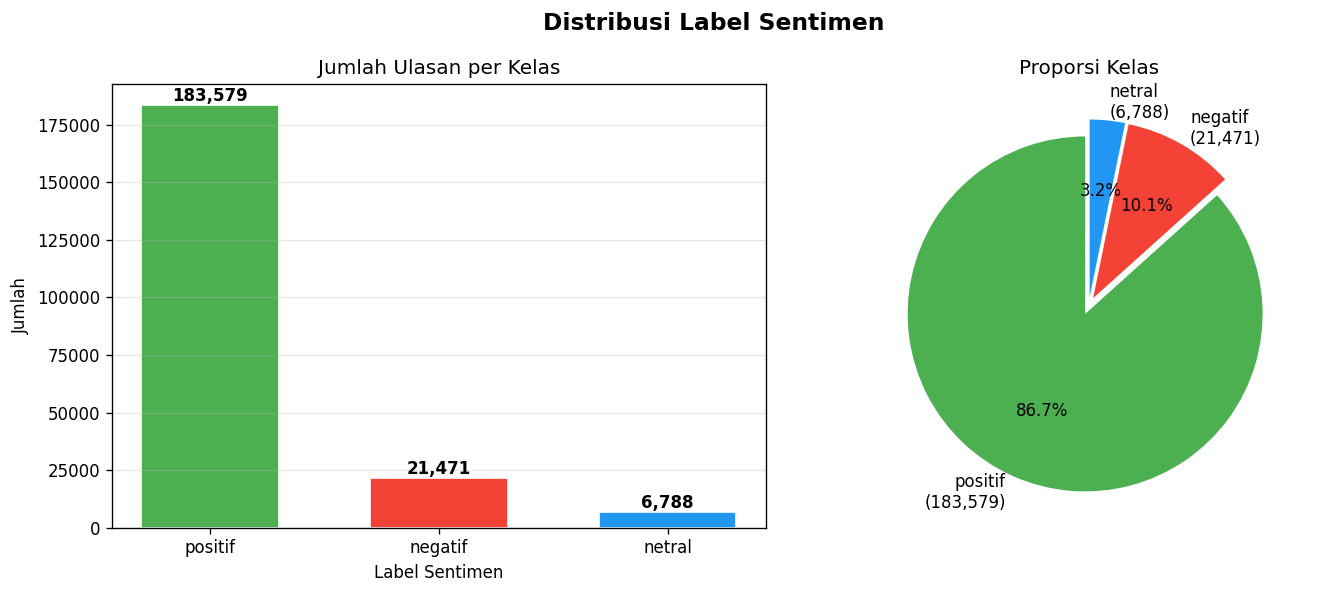

Grafik tersimpan.


In [ ]:
label_counts = df['label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Distribusi Label Sentimen', fontsize=14, fontweight='bold')

colors_bar = [COLORS[l] for l in label_counts.index]
bars = axes[0].bar(label_counts.index, label_counts.values,
                   color=colors_bar, edgecolor='white', width=0.6)
for bar, val in zip(bars, label_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 200,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Jumlah Ulasan per Kelas')
axes[0].set_ylabel('Jumlah')
axes[0].set_xlabel('Label Sentimen')
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(
    label_counts.values,
    labels=[f'{l}\n({v:,})' for l, v in zip(label_counts.index, label_counts.values)],
    autopct='%1.1f%%',
    colors=[COLORS[l] for l in label_counts.index],
    startangle=90,
    explode=[0.05] * len(label_counts)
)
axes[1].set_title('Proporsi Kelas')

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/eda_distribusi_label.png', bbox_inches='tight')
plt.show()
print("Grafik tersimpan.")

CELL 10 — EDA: Distribusi Rating

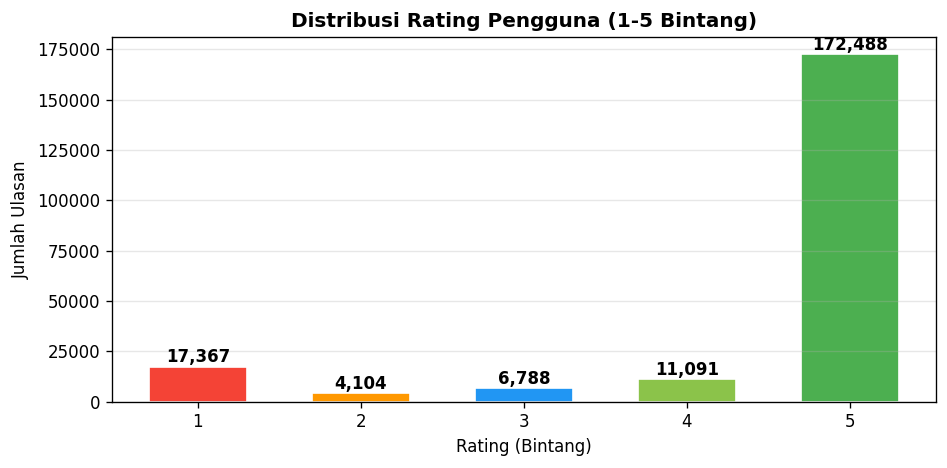

Grafik tersimpan.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
score_counts = df['score'].value_counts().sort_index()
score_colors = ['#F44336', '#FF9800', '#2196F3', '#8BC34A', '#4CAF50']

bars = ax.bar(score_counts.index.astype(str), score_counts.values,
              color=score_colors, edgecolor='white', width=0.6)
for bar, val in zip(bars, score_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 100,
            f'{val:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Distribusi Rating Pengguna (1-5 Bintang)', fontweight='bold')
ax.set_xlabel('Rating (Bintang)')
ax.set_ylabel('Jumlah Ulasan')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/eda_distribusi_rating.png', bbox_inches='tight')
plt.show()
print("Grafik tersimpan.")

CELL 11 — EDA: Panjang Teks

Statistik Panjang Karakter per Kelas:
            count    mean     std  min   25%   50%    75%     max
label                                                            
negatif   21471.0  101.64  102.53  1.0  30.0  67.0  136.0   614.0
netral     6788.0  111.16  104.77  1.0  35.0  76.0  154.0   544.0
positif  183579.0   75.84   83.19  1.0  22.0  47.0   98.0  2427.0

Statistik Jumlah Kata per Kelas:
            count   mean    std  min  25%   50%   75%    max
label                                                       
negatif   21471.0  16.70  16.49  1.0  5.0  11.0  22.0  130.0
netral     6788.0  18.02  16.51  1.0  6.0  13.0  25.0   93.0
positif  183579.0  11.69  12.84  1.0  3.0   7.0  15.0  331.0


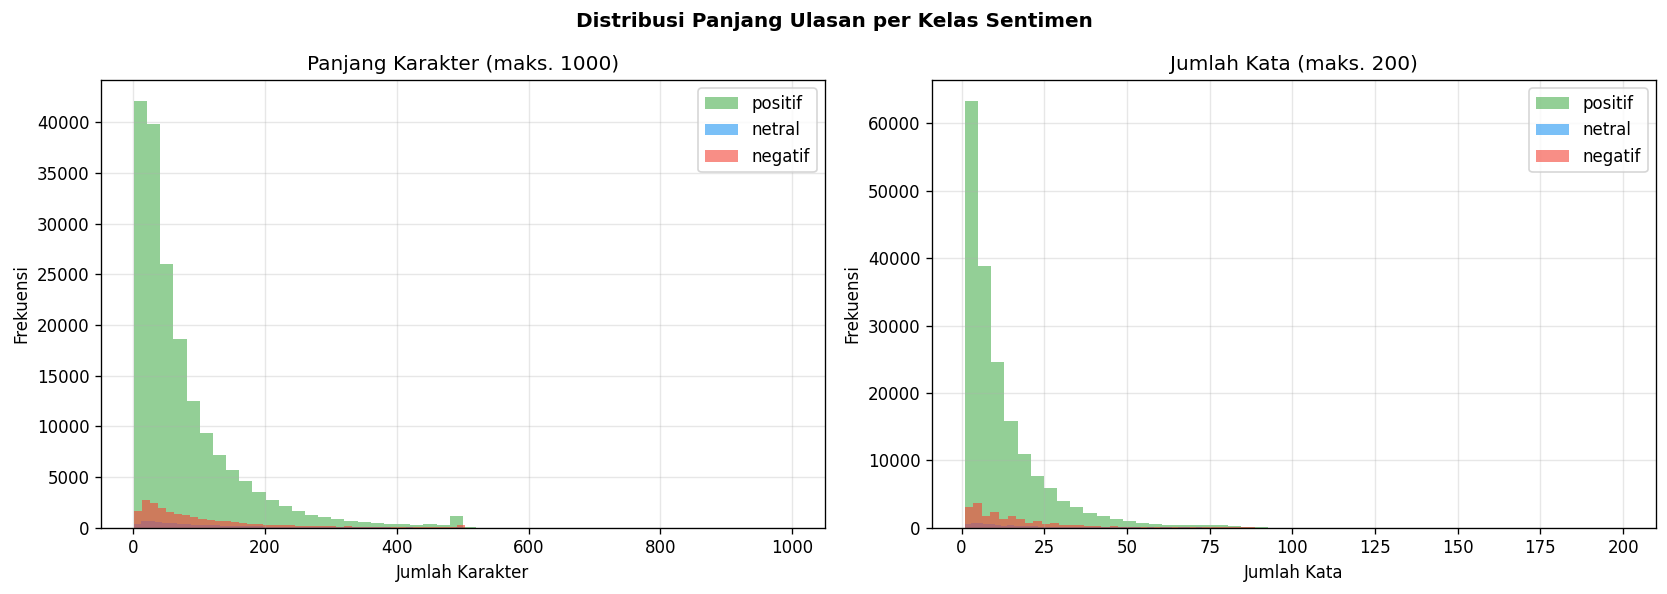

Grafik tersimpan.


In [ ]:
df['text_length'] = df['content'].astype(str).apply(len)
df['word_count']  = df['content'].astype(str).apply(lambda x: len(x.split()))

print("Statistik Panjang Karakter per Kelas:")
print(df.groupby('label')['text_length'].describe().round(2))
print("\nStatistik Jumlah Kata per Kelas:")
print(df.groupby('label')['word_count'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribusi Panjang Ulasan per Kelas Sentimen', fontweight='bold')

for label in ['positif', 'netral', 'negatif']:
    subset = df[df['label'] == label]
    axes[0].hist(subset['text_length'].clip(upper=1000),
                 bins=50, alpha=0.6, label=label, color=COLORS[label])
    axes[1].hist(subset['word_count'].clip(upper=200),
                 bins=50, alpha=0.6, label=label, color=COLORS[label])

axes[0].set_title('Panjang Karakter (maks. 1000)')
axes[0].set_xlabel('Jumlah Karakter')
axes[0].set_ylabel('Frekuensi')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].set_title('Jumlah Kata (maks. 200)')
axes[1].set_xlabel('Jumlah Kata')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/eda_panjang_teks.png', bbox_inches='tight')
plt.show()
print("Grafik tersimpan.")

CELL 12 — EDA: WordCloud

WordCloud positif selesai.
WordCloud netral selesai.
WordCloud negatif selesai.


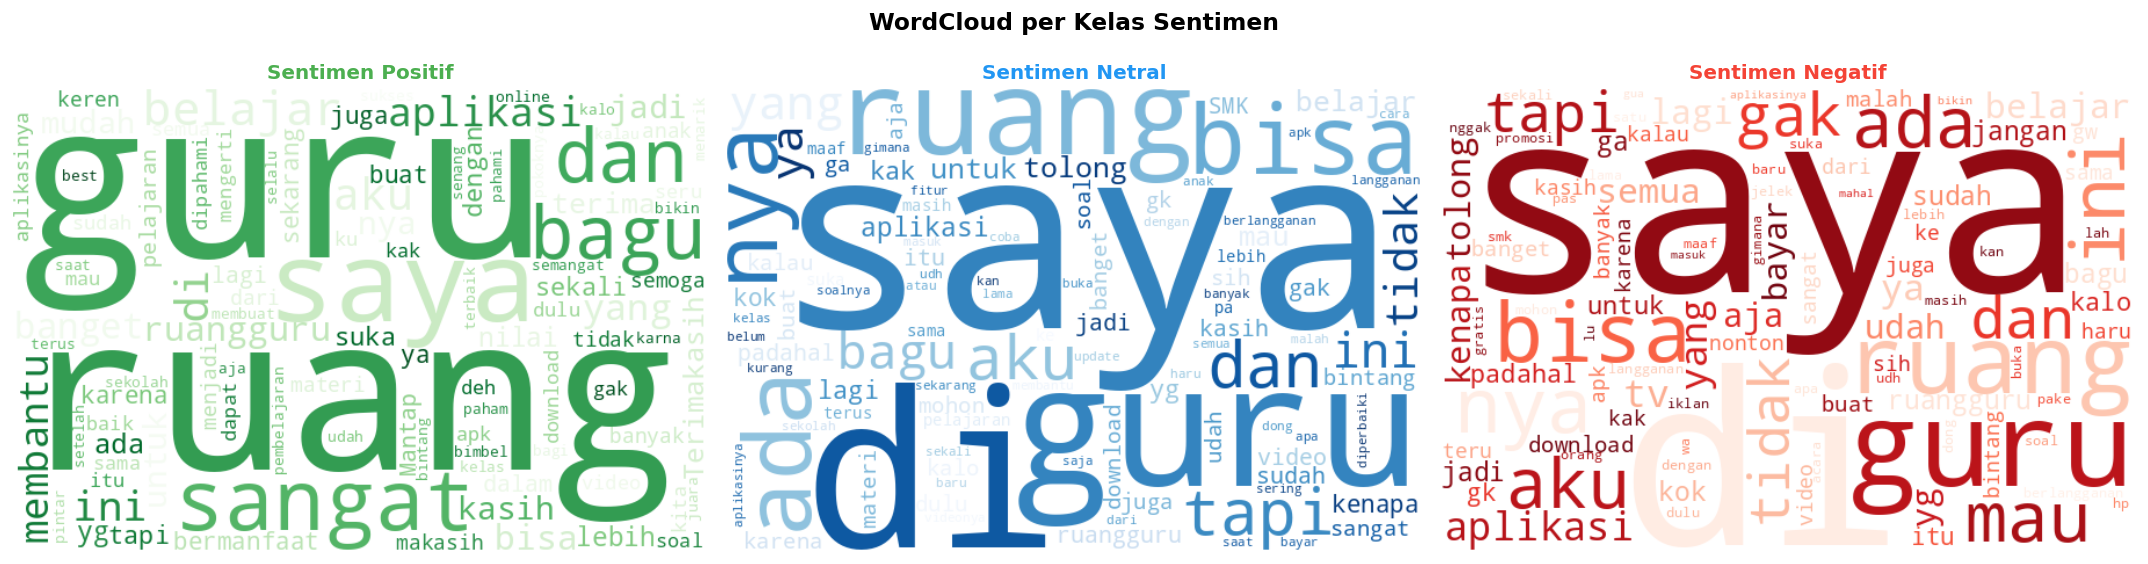

Grafik tersimpan.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('WordCloud per Kelas Sentimen', fontweight='bold', fontsize=14)

cmap_map = {'positif': 'Greens', 'netral': 'Blues', 'negatif': 'Reds'}

for ax, label in zip(axes, ['positif', 'netral', 'negatif']):
    subset = df[df['label'] == label]['content'].astype(str)
    if len(subset) > 5000:
        subset = subset.sample(5000, random_state=42)
    text_all = ' '.join(subset.tolist())
    wc = WordCloud(
        width=600, height=400,
        background_color='white',
        colormap=cmap_map[label],
        max_words=100,
        collocations=False
    ).generate(text_all)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'Sentimen {label.capitalize()}',
                 fontweight='bold', color=COLORS[label])
    ax.axis('off')
    print(f"WordCloud {label} selesai.")

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/eda_wordcloud.png', bbox_inches='tight')
plt.show()
print("Grafik tersimpan.")

CELL 13 — EDA: Cek Class Imbalance

In [ ]:
label_counts = df['label'].value_counts()
ir = label_counts.max() / label_counts.min()

print("=" * 55)
print("ANALISIS KETIDAKSEIMBANGAN KELAS")
print("=" * 55)
for lbl, cnt in label_counts.items():
    pct = cnt / len(df) * 100
    print(f"  {lbl:<10}: {cnt:>8,}  ({pct:.1f}%)")

print(f"\n  Imbalance Ratio (IR) = {ir:.2f}")
if ir > 1.5:
    print("\nDATASET TIDAK SEIMBANG (IR > 1.5)")
    print("Solusi yang akan diterapkan:")
    print("  (1) Tanpa Balancing (baseline)")
    print("  (2) Random Oversampling")
    print("  (3) Cost-Sensitive Learning (Weighted Loss)")
    print("  (4) Focal Loss")
    print("Metric utama: F1-Score (weighted)")
else:
    print("\nDataset relatif seimbang (IR <= 1.5)")

ANALISIS KETIDAKSEIMBANGAN KELAS
  positif   :  183,579  (86.7%)
  negatif   :   21,471  (10.1%)
  netral    :    6,788  (3.2%)

  Imbalance Ratio (IR) = 27.04

DATASET TIDAK SEIMBANG (IR > 1.5)
Solusi yang akan diterapkan:
  (1) Tanpa Balancing (baseline)
  (2) Random Oversampling
  (3) Cost-Sensitive Learning (Weighted Loss)
  (4) Focal Loss
Metric utama: F1-Score (weighted)


CELL 14 — Preprocessing (dengan checkpoint)

In [ ]:
CHECKPOINT_PREP = f'{DRIVE_PATH}/checkpoint_preprocessing.pkl'

if os.path.exists(CHECKPOINT_PREP):
    with open(CHECKPOINT_PREP, 'rb') as f:
        ckpt = pickle.load(f)
    df            = ckpt['df']
    label_map     = ckpt['label_map']
    label_map_inv = ckpt['label_map_inv']
    print(f"Checkpoint preprocessing ditemukan. {len(df):,} baris.")
else:
    stop_factory     = StopWordRemoverFactory()
    stopword_remover = stop_factory.create_stop_word_remover()

    def preprocess_text(text):
        text = str(text).lower()
        text = re.sub(r'http\S+|www\.\S+', '', text)
        text = re.sub(r'@\w+|#\w+', '', text)
        text = re.sub(r'[^a-z0-9\s]', ' ', text)
        text = re.sub(r'\d+', '', text)
        text = re.sub(r'\s+', ' ', text).strip()
        text = stopword_remover.remove(text)
        return text

    print("Memproses teks, harap tunggu...")
    df['content_clean'] = df['content'].apply(preprocess_text)
    df = df[df['content_clean'].str.strip() != ''].reset_index(drop=True)

    label_map     = {'negatif': 0, 'netral': 1, 'positif': 2}
    label_map_inv = {v: k for k, v in label_map.items()}
    df['label_enc'] = df['label'].map(label_map)

    with open(CHECKPOINT_PREP, 'wb') as f:
        pickle.dump({
            'df'           : df,
            'label_map'    : label_map,
            'label_map_inv': label_map_inv
        }, f)

    df.to_csv(f'{DRIVE_PATH}/dataset_clean.csv', index=False)
    print(f"Preprocessing selesai. Total: {len(df):,} baris.")

display(df[['content', 'content_clean', 'label', 'label_enc']].head())

Checkpoint preprocessing ditemukan. 209,343 baris.


,content,content_clean,label,label_enc
0,Aplikasi bimbel TERBAIK INI.Mulai dari video y...,aplikasi bimbel terbaik mulai video menarik se...,positif,2
1,"Bruh, padahal udh langganan tapi ada aja mater...",bruh padahal udh langganan aja materi yg ga ak...,negatif,0
2,"Sering banget ngebug, ngefreeze juga, trs lemo...",sering banget ngebug ngefreeze trs lemot padah...,negatif,0
3,Edit lagi... Setahun lalu saya rating komplain...,edit setahun lalu rating komplain ruangguru ke...,negatif,0
4,Aplikasinya ngebantu bgt buat belajar soalnya ...,aplikasinya ngebantu bgt buat belajar soalnya ...,positif,2


CELL 15 — Sampling dan Balancing (dengan checkpoint)

In [ ]:
CHECKPOINT_SAMPLE = f'{DRIVE_PATH}/checkpoint_sample.pkl'

if os.path.exists(CHECKPOINT_SAMPLE):
    with open(CHECKPOINT_SAMPLE, 'rb') as f:
        ckpt = pickle.load(f)
    df_sample       = ckpt['df_sample']
    texts_raw       = ckpt['texts_raw']
    labels_raw      = ckpt['labels_raw']
    texts_balanced  = ckpt['texts_balanced']
    labels_balanced = ckpt['labels_balanced']
    print(f"Checkpoint sampling ditemukan.")
    print(f"  texts_raw      : {len(texts_raw):,}")
    print(f"  texts_balanced : {len(texts_balanced):,}")
else:
    df_sample = (
        df.groupby('label', group_keys=False)
          .apply(lambda x: x.sample(min(len(x), SAMPLE_PER_CLASS), random_state=42))
          .reset_index(drop=True)
    )
    print(f"Stratified sampling: {SAMPLE_PER_CLASS} per kelas")
    print(df_sample['label'].value_counts())

    texts_raw  = df_sample['content_clean'].tolist()
    labels_raw = df_sample['label_enc'].tolist()

    texts_arr  = np.array(texts_raw)
    labels_arr = np.array(labels_raw)
    indices    = np.arange(len(texts_arr)).reshape(-1, 1)
    ros        = RandomOverSampler(sampling_strategy='auto', random_state=42)
    idx_res, labels_balanced_arr = ros.fit_resample(indices, labels_arr)

    texts_balanced  = texts_arr[idx_res.flatten()].tolist()
    labels_balanced = labels_balanced_arr.tolist()

    print(f"\nDistribusi setelah balancing:")
    for k, v in sorted(Counter(labels_balanced).items()):
        print(f"  {label_map_inv[k]:<10}: {v:,}")

    with open(CHECKPOINT_SAMPLE, 'wb') as f:
        pickle.dump({
            'df_sample'      : df_sample,
            'texts_raw'      : texts_raw,
            'labels_raw'     : labels_raw,
            'texts_balanced' : texts_balanced,
            'labels_balanced': labels_balanced,
        }, f)
    print("\nCheckpoint sampling tersimpan.")

Checkpoint sampling ditemukan.
  texts_raw      : 9,000
  texts_balanced : 9,000


CELL 16 — Visualisasi Balancing

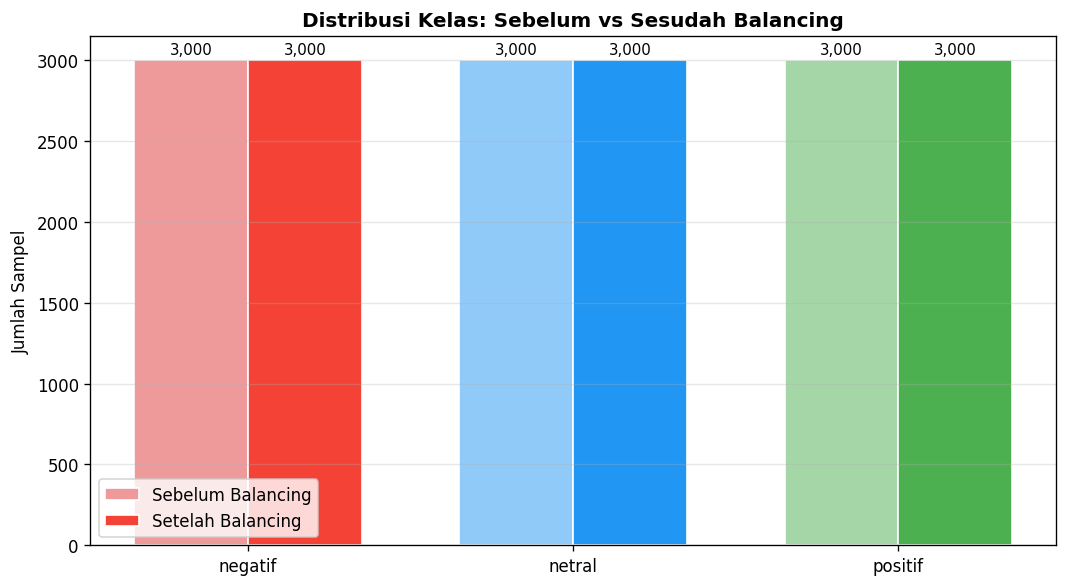

Grafik tersimpan.


In [ ]:
before      = Counter(labels_raw)
after       = Counter(labels_balanced)
label_names = ['negatif', 'netral', 'positif']
x     = np.arange(3)
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - width/2, [before.get(i, 0) for i in range(3)], width,
            label='Sebelum Balancing',
            color=['#EF9A9A', '#90CAF9', '#A5D6A7'], edgecolor='white')
b2 = ax.bar(x + width/2, [after.get(i, 0) for i in range(3)], width,
            label='Setelah Balancing',
            color=['#F44336', '#2196F3', '#4CAF50'], edgecolor='white')

for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 20,
            f'{int(bar.get_height()):,}',
            ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(label_names)
ax.set_title('Distribusi Kelas: Sebelum vs Sesudah Balancing', fontweight='bold')
ax.set_ylabel('Jumlah Sampel')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/eda_balancing.png', bbox_inches='tight')
plt.show()
print("Grafik tersimpan.")

CELL 17 — Hitung Class Weight

In [ ]:
classes             = np.array([0, 1, 2])
class_weights       = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=np.array(labels_raw)
)
class_weight_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

# Focal alpha menggunakan class weight yang sama
focal_alpha_tensor  = torch.tensor(class_weights, dtype=torch.float).to(device)

print("Class Weight:")
print(f"  negatif (0) : {class_weights[0]:.4f}")
print(f"  netral  (1) : {class_weights[1]:.4f}")
print(f"  positif (2) : {class_weights[2]:.4f}")
print()
print("Focal Loss parameter:")
print(f"  gamma  = 2.0")
print(f"  alpha  = class weights di atas")

Class Weight:
  negatif (0) : 1.0000
  netral  (1) : 1.0000
  positif (2) : 1.0000

Focal Loss parameter:
  gamma  = 2.0
  alpha  = class weights di atas


CELL 18 — 10-Fold CV Tanpa Balancing (dengan checkpoint)

In [ ]:
CHECKPOINT_CV1 = f'{DRIVE_PATH}/checkpoint_cv_tanpa_balancing.pkl'

if os.path.exists(CHECKPOINT_CV1):
    with open(CHECKPOINT_CV1, 'rb') as f:
        result_no_balance = pickle.load(f)
    print(f"Checkpoint CV tanpa balancing ditemukan.")
    print(f"  avg_f1   = {result_no_balance['avg_f1']:.4f}")
    print(f"  avg_acc  = {result_no_balance['avg_acc']:.4f}")
    print(f"  fold_f1s = {[round(x,4) for x in result_no_balance['fold_f1s']]}")
else:
    result_no_balance = run_10fold_cv(
        texts_raw, labels_raw,
        tag='tanpa_balancing',
        mode='standard'
    )
    with open(CHECKPOINT_CV1, 'wb') as f:
        pickle.dump(result_no_balance, f)
    print("Checkpoint CV tanpa balancing tersimpan.")


10-FOLD CV | TANPA_BALANCING | mode: standard

Fold 1/10


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8087
  Epoch 2/3 | Loss: 0.6373
  Epoch 3/3 | Loss: 0.4774
  Hasil | F1: 0.7219 | Accuracy: 0.7233

Fold 2/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.7950
  Epoch 2/3 | Loss: 0.6231
  Epoch 3/3 | Loss: 0.4470
  Hasil | F1: 0.6837 | Accuracy: 0.6844

Fold 3/10


... (12 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8090
  Epoch 2/3 | Loss: 0.6309
  Epoch 3/3 | Loss: 0.4691
  Hasil | F1: 0.6995 | Accuracy: 0.7011

Fold 10/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8089
  Epoch 2/3 | Loss: 0.6297
  Epoch 3/3 | Loss: 0.4677
  Hasil | F1: 0.6939 | Accuracy: 0.6956

────────────────────────────────────────────────────────────
HASIL AKHIR | tanpa_balancing
  F1-Score (weighted) : 0.6951 +/- 0.0138
  Accuracy            : 0.6970 +/- 0.0133
────────────────────────────────────────────────────────────
Checkpoint CV tanpa balancing tersimpan.


CELL 19 —  10-Fold CV Dengan Balancing (dengan checkpoint)

In [ ]:
CHECKPOINT_CV2 = f'{DRIVE_PATH}/checkpoint_cv_dengan_balancing.pkl'

if os.path.exists(CHECKPOINT_CV2):
    with open(CHECKPOINT_CV2, 'rb') as f:
        result_balanced = pickle.load(f)
    print(f"Checkpoint CV dengan balancing ditemukan.")
    print(f"  avg_f1   = {result_balanced['avg_f1']:.4f}")
    print(f"  avg_acc  = {result_balanced['avg_acc']:.4f}")
    print(f"  fold_f1s = {[round(x,4) for x in result_balanced['fold_f1s']]}")
else:
    result_balanced = run_10fold_cv(
        texts_balanced, labels_balanced,
        tag='dengan_balancing',
        mode='standard'
    )
    with open(CHECKPOINT_CV2, 'wb') as f:
        pickle.dump(result_balanced, f)
    print("Checkpoint CV dengan balancing tersimpan.")


10-FOLD CV | DENGAN_BALANCING | mode: standard

Fold 1/10


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8106
  Epoch 2/3 | Loss: 0.6348
  Epoch 3/3 | Loss: 0.4722
  Hasil | F1: 0.7175 | Accuracy: 0.7200

Fold 2/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8114
  Epoch 2/3 | Loss: 0.6278
  Epoch 3/3 | Loss: 0.4617
  Hasil | F1: 0.7015 | Accuracy: 0.7022

Fold 3/10


... (12 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8080
  Epoch 2/3 | Loss: 0.6306
  Epoch 3/3 | Loss: 0.4658
  Hasil | F1: 0.6932 | Accuracy: 0.6956

Fold 10/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8116
  Epoch 2/3 | Loss: 0.6312
  Epoch 3/3 | Loss: 0.4592
  Hasil | F1: 0.7058 | Accuracy: 0.7067

────────────────────────────────────────────────────────────
HASIL AKHIR | dengan_balancing
  F1-Score (weighted) : 0.6927 +/- 0.0134
  Accuracy            : 0.6951 +/- 0.0128
────────────────────────────────────────────────────────────
Checkpoint CV dengan balancing tersimpan.


CELL 20 — 10-Fold CV Cost-Sensitive Learning (dengan checkpoint)

In [ ]:
CHECKPOINT_CV3 = f'{DRIVE_PATH}/checkpoint_cv_cost_sensitive.pkl'

if os.path.exists(CHECKPOINT_CV3):
    with open(CHECKPOINT_CV3, 'rb') as f:
        result_cost_sensitive = pickle.load(f)
    print(f"Checkpoint CV cost-sensitive ditemukan.")
    print(f"  avg_f1   = {result_cost_sensitive['avg_f1']:.4f}")
    print(f"  avg_acc  = {result_cost_sensitive['avg_acc']:.4f}")
    print(f"  fold_f1s = {[round(x,4) for x in result_cost_sensitive['fold_f1s']]}")
else:
    result_cost_sensitive = run_10fold_cv(
        texts_raw, labels_raw,
        tag='cost_sensitive_learning',
        mode='weighted',
        class_weights=class_weight_tensor
    )
    with open(CHECKPOINT_CV3, 'wb') as f:
        pickle.dump(result_cost_sensitive, f)
    print("Checkpoint CV cost-sensitive tersimpan.")


10-FOLD CV | COST_SENSITIVE_LEARNING | mode: weighted

Fold 1/10


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8040
  Epoch 2/3 | Loss: 0.6276
  Epoch 3/3 | Loss: 0.4589
  Hasil | F1: 0.7186 | Accuracy: 0.7211

Fold 2/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8109
  Epoch 2/3 | Loss: 0.6280
  Epoch 3/3 | Loss: 0.4586
  Hasil | F1: 0.6995 | Accuracy: 0.7000

Fold 3/10


... (12 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8103
  Epoch 2/3 | Loss: 0.6367
  Epoch 3/3 | Loss: 0.4624
  Hasil | F1: 0.7047 | Accuracy: 0.7067

Fold 10/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.8078
  Epoch 2/3 | Loss: 0.6261
  Epoch 3/3 | Loss: 0.4603
  Hasil | F1: 0.6979 | Accuracy: 0.7000

────────────────────────────────────────────────────────────
HASIL AKHIR | cost_sensitive_learning
  F1-Score (weighted) : 0.6920 +/- 0.0152
  Accuracy            : 0.6943 +/- 0.0148
────────────────────────────────────────────────────────────
Checkpoint CV cost-sensitive tersimpan.


CELL 21 — 10-Fold CV Focal Loss (dengan checkpoint)

In [ ]:
CHECKPOINT_CV4 = f'{DRIVE_PATH}/checkpoint_cv_focal_loss.pkl'

if os.path.exists(CHECKPOINT_CV4):
    with open(CHECKPOINT_CV4, 'rb') as f:
        result_focal = pickle.load(f)
    print(f"Checkpoint CV focal loss ditemukan.")
    print(f"  avg_f1   = {result_focal['avg_f1']:.4f}")
    print(f"  avg_acc  = {result_focal['avg_acc']:.4f}")
    print(f"  fold_f1s = {[round(x,4) for x in result_focal['fold_f1s']]}")
else:
    result_focal = run_10fold_cv(
        texts_raw, labels_raw,
        tag='focal_loss',
        mode='focal',
        focal_gamma=2.0,
        focal_alpha=focal_alpha_tensor
    )
    with open(CHECKPOINT_CV4, 'wb') as f:
        pickle.dump(result_focal, f)
    print("Checkpoint CV focal loss tersimpan.")


10-FOLD CV | FOCAL_LOSS | mode: focal

Fold 1/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.3419
  Epoch 2/3 | Loss: 0.2574
  Epoch 3/3 | Loss: 0.1857
  Hasil | F1: 0.7232 | Accuracy: 0.7256

Fold 2/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.3395
  Epoch 2/3 | Loss: 0.2545
  Epoch 3/3 | Loss: 0.1752
  Hasil | F1: 0.6851 | Accuracy: 0.6856

Fold 3/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (11 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.3424
  Epoch 2/3 | Loss: 0.2533
  Epoch 3/3 | Loss: 0.1756
  Hasil | F1: 0.6878 | Accuracy: 0.6911

Fold 10/10


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1/3 | Loss: 0.3378
  Epoch 2/3 | Loss: 0.2527
  Epoch 3/3 | Loss: 0.1758
  Hasil | F1: 0.7041 | Accuracy: 0.7056

────────────────────────────────────────────────────────────
HASIL AKHIR | focal_loss
  F1-Score (weighted) : 0.6922 +/- 0.0183
  Accuracy            : 0.6942 +/- 0.0175
────────────────────────────────────────────────────────────
Checkpoint CV focal loss tersimpan.


CELL RECOVERY

In [ ]:
# Load semua checkpoint hasil CV yang sudah tersimpan di Drive
import pickle

# Load CV tanpa balancing
CHECKPOINT_CV1 = f'{DRIVE_PATH}/checkpoint_cv_tanpa_balancing.pkl'
with open(CHECKPOINT_CV1, 'rb') as f:
    result_no_balance = pickle.load(f)
print(f"CV Tanpa Balancing loaded | avg_f1 = {result_no_balance['avg_f1']:.4f}")

# Load CV dengan balancing
CHECKPOINT_CV2 = f'{DRIVE_PATH}/checkpoint_cv_dengan_balancing.pkl'
with open(CHECKPOINT_CV2, 'rb') as f:
    result_balanced = pickle.load(f)
print(f"CV Dengan Balancing loaded | avg_f1 = {result_balanced['avg_f1']:.4f}")

# Load CV cost-sensitive
CHECKPOINT_CV3 = f'{DRIVE_PATH}/checkpoint_cv_cost_sensitive.pkl'
with open(CHECKPOINT_CV3, 'rb') as f:
    result_cost_sensitive = pickle.load(f)
print(f"CV Cost-Sensitive loaded   | avg_f1 = {result_cost_sensitive['avg_f1']:.4f}")

# Load CV focal loss
CHECKPOINT_CV4 = f'{DRIVE_PATH}/checkpoint_cv_focal_loss.pkl'
with open(CHECKPOINT_CV4, 'rb') as f:
    result_focal = pickle.load(f)
print(f"CV Focal Loss loaded       | avg_f1 = {result_focal['avg_f1']:.4f}")

print("\nSemua hasil CV berhasil di-load. Lanjut ke Cell 22.")

CV Tanpa Balancing loaded | avg_f1 = 0.6951
CV Dengan Balancing loaded | avg_f1 = 0.6927
CV Cost-Sensitive loaded   | avg_f1 = 0.6920
CV Focal Loss loaded       | avg_f1 = 0.6922

Semua hasil CV berhasil di-load. Lanjut ke Cell 22.


CELL 22 — Perbandingan Empat Skenario

In [ ]:
all_results = {
    'Tanpa Balancing'         : result_no_balance['avg_f1'],
    'Random Oversampling'     : result_balanced['avg_f1'],
    'Cost-Sensitive Learning' : result_cost_sensitive['avg_f1'],
    'Focal Loss'              : result_focal['avg_f1'],
}

print("=" * 80)
print("PERBANDINGAN HASIL 10-FOLD CROSS VALIDATION - EMPAT SKENARIO")
print("Model: IndoBERT-base (indobenchmark/indobert-base-p1)")
print("=" * 80)
print(f"{'Skenario':<42} {'F1-Score (weighted)':<24} {'Accuracy'}")
print(f"{'-'*42} {'-'*24} {'-'*10}")
print(f"{'(1) Tanpa Balancing':<42} "
      f"{result_no_balance['avg_f1']:.4f} +/- {result_no_balance['std_f1']:.4f}      "
      f"{result_no_balance['avg_acc']:.4f}")
print(f"{'(2) Random Oversampling':<42} "
      f"{result_balanced['avg_f1']:.4f} +/- {result_balanced['std_f1']:.4f}      "
      f"{result_balanced['avg_acc']:.4f}")
print(f"{'(3) Cost-Sensitive Learning':<42} "
      f"{result_cost_sensitive['avg_f1']:.4f} +/- {result_cost_sensitive['std_f1']:.4f}      "
      f"{result_cost_sensitive['avg_acc']:.4f}")
print(f"{'(4) Focal Loss':<42} "
      f"{result_focal['avg_f1']:.4f} +/- {result_focal['std_f1']:.4f}      "
      f"{result_focal['avg_acc']:.4f}")
print("=" * 80)

best_name = max(all_results, key=all_results.get)
best_val  = all_results[best_name]
print(f"\nSkenario Terbaik : {best_name}")
print(f"F1-Score Terbaik : {best_val:.4f}")

PERBANDINGAN HASIL 10-FOLD CROSS VALIDATION - EMPAT SKENARIO
Model: IndoBERT-base (indobenchmark/indobert-base-p1)
Skenario                                   F1-Score (weighted)      Accuracy
------------------------------------------ ------------------------ ----------
(1) Tanpa Balancing                        0.6951 +/- 0.0138      0.6970
(2) Random Oversampling                    0.6927 +/- 0.0134      0.6951
(3) Cost-Sensitive Learning                0.6920 +/- 0.0152      0.6943
(4) Focal Loss                             0.6922 +/- 0.0183      0.6942

Skenario Terbaik : Tanpa Balancing
F1-Score Terbaik : 0.6951


CELL 23 — Visualisasi Perbandingan Empat Skenario

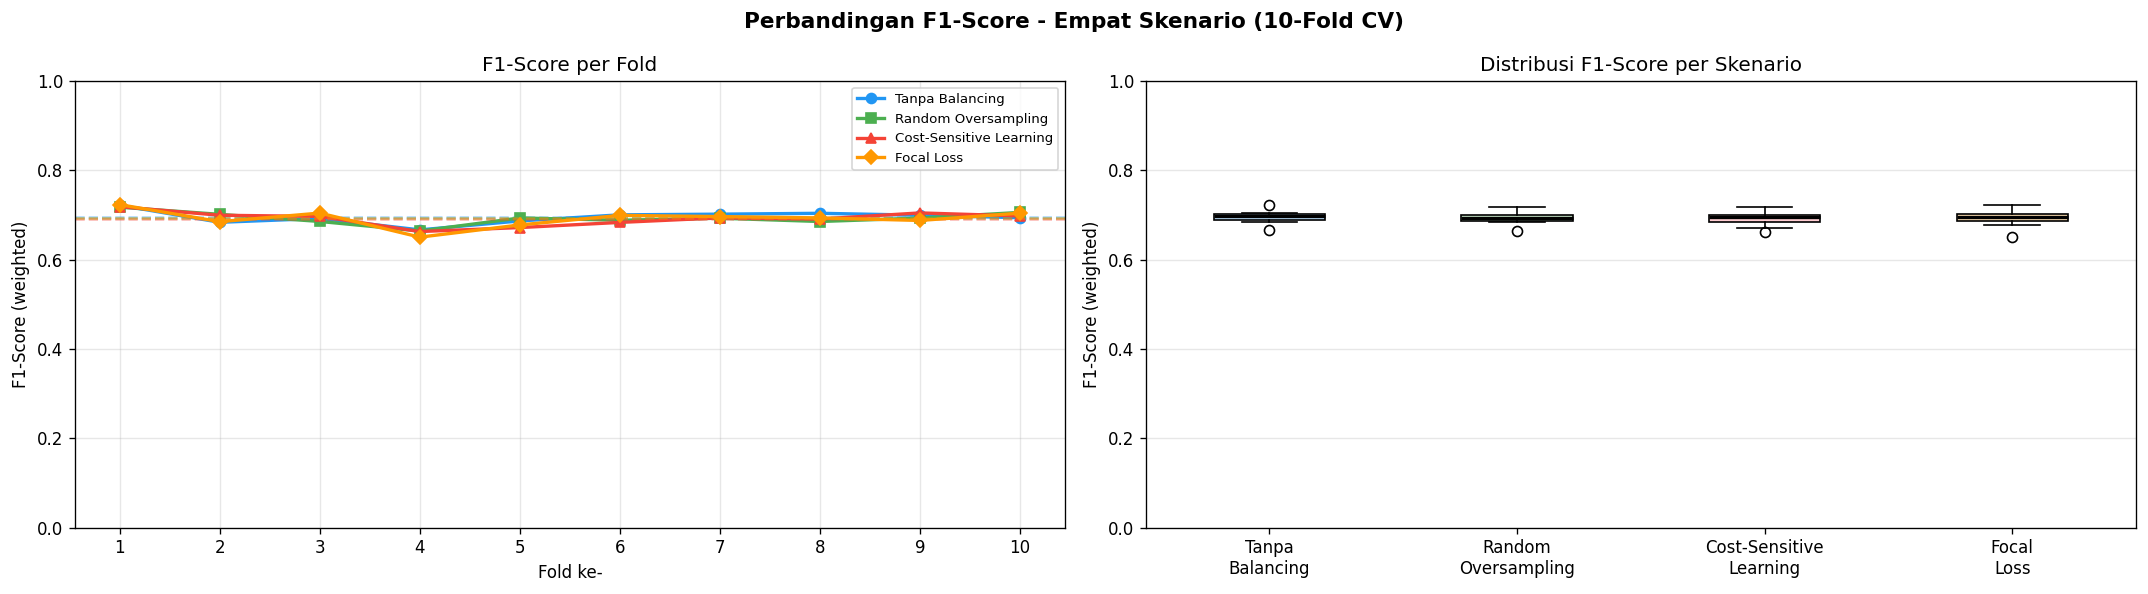

In [ ]:
folds = list(range(1, 11))

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle('Perbandingan F1-Score - Empat Skenario (10-Fold CV)',
             fontweight='bold', fontsize=13)

plot_data = [
    (result_no_balance['fold_f1s'],     'o-', '#2196F3', 'Tanpa Balancing'),
    (result_balanced['fold_f1s'],       's-', '#4CAF50', 'Random Oversampling'),
    (result_cost_sensitive['fold_f1s'], '^-', '#F44336', 'Cost-Sensitive Learning'),
    (result_focal['fold_f1s'],          'D-', '#FF9800', 'Focal Loss'),
]

for fold_f1s, marker, color, label in plot_data:
    axes[0].plot(folds, fold_f1s, marker, color=color,
                 label=label, linewidth=2, markersize=6)
    axes[0].axhline(np.mean(fold_f1s), color=color, linestyle='--', alpha=0.4)

axes[0].set_title('F1-Score per Fold')
axes[0].set_xlabel('Fold ke-')
axes[0].set_ylabel('F1-Score (weighted)')
axes[0].set_xticks(folds)
axes[0].legend(fontsize=8)
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.3)

bp = axes[1].boxplot(
    [result_no_balance['fold_f1s'],
     result_balanced['fold_f1s'],
     result_cost_sensitive['fold_f1s'],
     result_focal['fold_f1s']],
    labels=['Tanpa\nBalancing', 'Random\nOversampling',
            'Cost-Sensitive\nLearning', 'Focal\nLoss'],
    patch_artist=True
)
for patch, color in zip(bp['boxes'], ['#BBDEFB', '#C8E6C9', '#FFCDD2', '#FFE0B2']):
    patch.set_facecolor(color)
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)

axes[1].set_title('Distribusi F1-Score per Skenario')
axes[1].set_ylabel('F1-Score (weighted)')
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/perbandingan_empat_skenario.png', dpi=150, bbox_inches='tight')
plt.show()

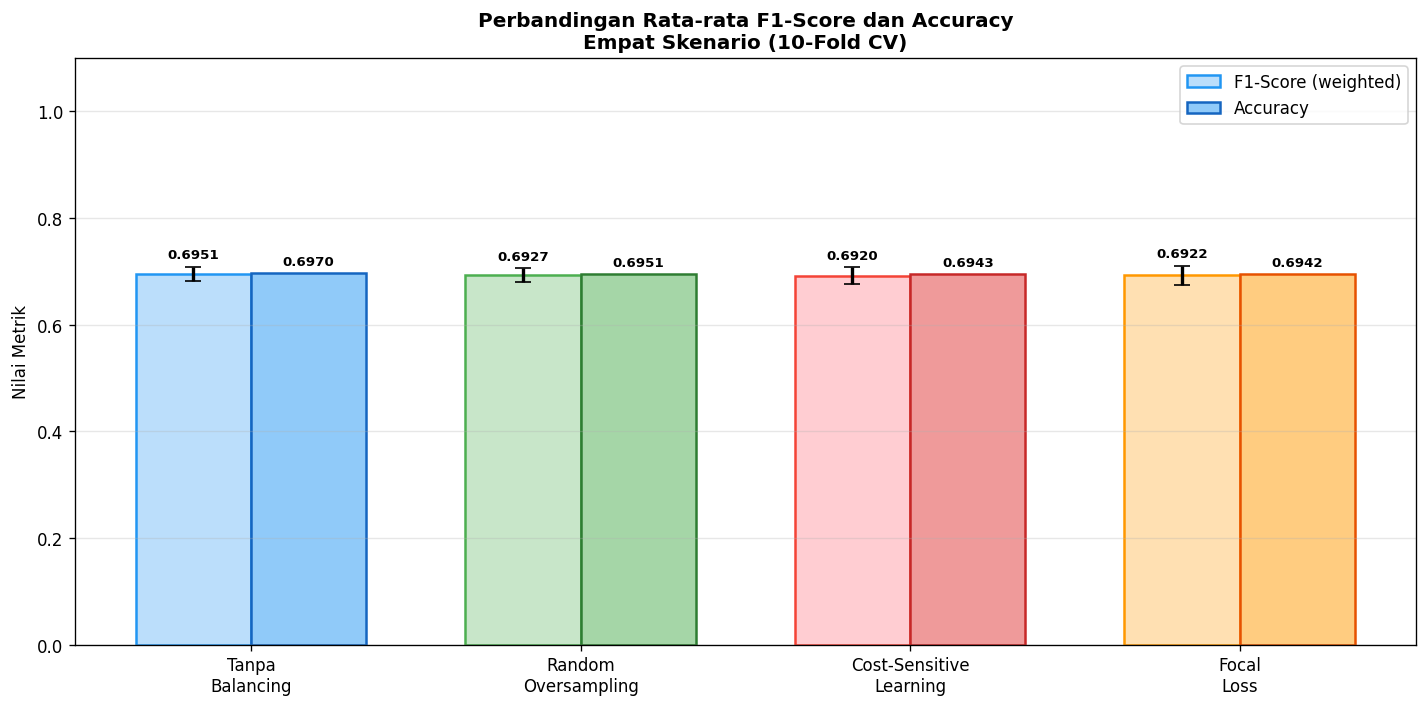

Grafik tersimpan.


In [ ]:
# Bar chart rata-rata F1 dan Accuracy empat skenario
skenario_labels = ['Tanpa\nBalancing', 'Random\nOversampling',
                   'Cost-Sensitive\nLearning', 'Focal\nLoss']
avg_f1s  = [result_no_balance['avg_f1'],  result_balanced['avg_f1'],
            result_cost_sensitive['avg_f1'], result_focal['avg_f1']]
std_f1s  = [result_no_balance['std_f1'],  result_balanced['std_f1'],
            result_cost_sensitive['std_f1'], result_focal['std_f1']]
avg_accs = [result_no_balance['avg_acc'], result_balanced['avg_acc'],
            result_cost_sensitive['avg_acc'], result_focal['avg_acc']]

x     = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars_f1 = ax.bar(x - width/2, avg_f1s, width,
                 yerr=std_f1s, capsize=5,
                 label='F1-Score (weighted)',
                 color=['#BBDEFB', '#C8E6C9', '#FFCDD2', '#FFE0B2'],
                 edgecolor=['#2196F3', '#4CAF50', '#F44336', '#FF9800'],
                 linewidth=1.5, error_kw={'linewidth': 2})
bars_ac = ax.bar(x + width/2, avg_accs, width,
                 label='Accuracy',
                 color=['#90CAF9', '#A5D6A7', '#EF9A9A', '#FFCC80'],
                 edgecolor=['#1565C0', '#2E7D32', '#C62828', '#E65100'],
                 linewidth=1.5)

for bar, val, std in zip(bars_f1, avg_f1s, std_f1s):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + std + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
for bar, val in zip(bars_ac, avg_accs):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(skenario_labels)
ax.set_ylabel('Nilai Metrik')
ax.set_title('Perbandingan Rata-rata F1-Score dan Accuracy\nEmpat Skenario (10-Fold CV)',
             fontweight='bold')
ax.legend()
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/bar_perbandingan_metrik.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik tersimpan.")

CELL 24 — Confusion Matrix Empat Skenario (dengan checkpoint)

In [ ]:
CHECKPOINT_CM = f'{DRIVE_PATH}/checkpoint_confusion_matrix.pkl'

if os.path.exists(CHECKPOINT_CM):
    with open(CHECKPOINT_CM, 'rb') as f:
        ckpt = pickle.load(f)
    preds_nb = ckpt['preds_nb']
    true_nb  = ckpt['true_nb']
    f1_nb    = ckpt['f1_nb']
    preds_wb = ckpt['preds_wb']
    true_wb  = ckpt['true_wb']
    f1_wb    = ckpt['f1_wb']
    preds_cs = ckpt['preds_cs']
    true_cs  = ckpt['true_cs']
    f1_cs    = ckpt['f1_cs']
    preds_fl = ckpt['preds_fl']
    true_fl  = ckpt['true_fl']
    f1_fl    = ckpt['f1_fl']
    print("Checkpoint confusion matrix ditemukan.")
else:
    preds_nb, true_nb, f1_nb, _, _, _ = run_split_eval(
        texts_raw, labels_raw,
        tag='Tanpa Balancing', mode='standard'
    )
    preds_wb, true_wb, f1_wb, _, _, _ = run_split_eval(
        texts_balanced, labels_balanced,
        tag='Random Oversampling', mode='standard'
    )
    preds_cs, true_cs, f1_cs, _, _, _ = run_split_eval(
        texts_raw, labels_raw,
        tag='Cost-Sensitive Learning',
        mode='weighted', class_weights=class_weight_tensor
    )
    preds_fl, true_fl, f1_fl, _, _, _ = run_split_eval(
        texts_raw, labels_raw,
        tag='Focal Loss',
        mode='focal', focal_gamma=2.0, focal_alpha=focal_alpha_tensor
    )
    with open(CHECKPOINT_CM, 'wb') as f:
        pickle.dump({
            'preds_nb': preds_nb, 'true_nb': true_nb, 'f1_nb': f1_nb,
            'preds_wb': preds_wb, 'true_wb': true_wb, 'f1_wb': f1_wb,
            'preds_cs': preds_cs, 'true_cs': true_cs, 'f1_cs': f1_cs,
            'preds_fl': preds_fl, 'true_fl': true_fl, 'f1_fl': f1_fl,
        }, f)
    print("Checkpoint confusion matrix tersimpan.")

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training | Tanpa Balancing
  Epoch 1/3 | Loss: 0.8200
  Epoch 2/3 | Loss: 0.6295
  Epoch 3/3 | Loss: 0.4592
  Selesai | F1: 0.6901 | Accuracy: 0.6922


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training | Random Oversampling
  Epoch 1/3 | Loss: 0.8200
  Epoch 2/3 | Loss: 0.6308
  Epoch 3/3 | Loss: 0.4693
  Selesai | F1: 0.6986 | Accuracy: 0.7011


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training | Cost-Sensitive Learning
  Epoch 1/3 | Loss: 0.8267
  Epoch 2/3 | Loss: 0.6347
  Epoch 3/3 | Loss: 0.4650
  Selesai | F1: 0.6977 | Accuracy: 0.7011


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training | Focal Loss
  Epoch 1/3 | Loss: 0.3473
  Epoch 2/3 | Loss: 0.2584
  Epoch 3/3 | Loss: 0.1806
  Selesai | F1: 0.6959 | Accuracy: 0.6972
Checkpoint confusion matrix tersimpan.


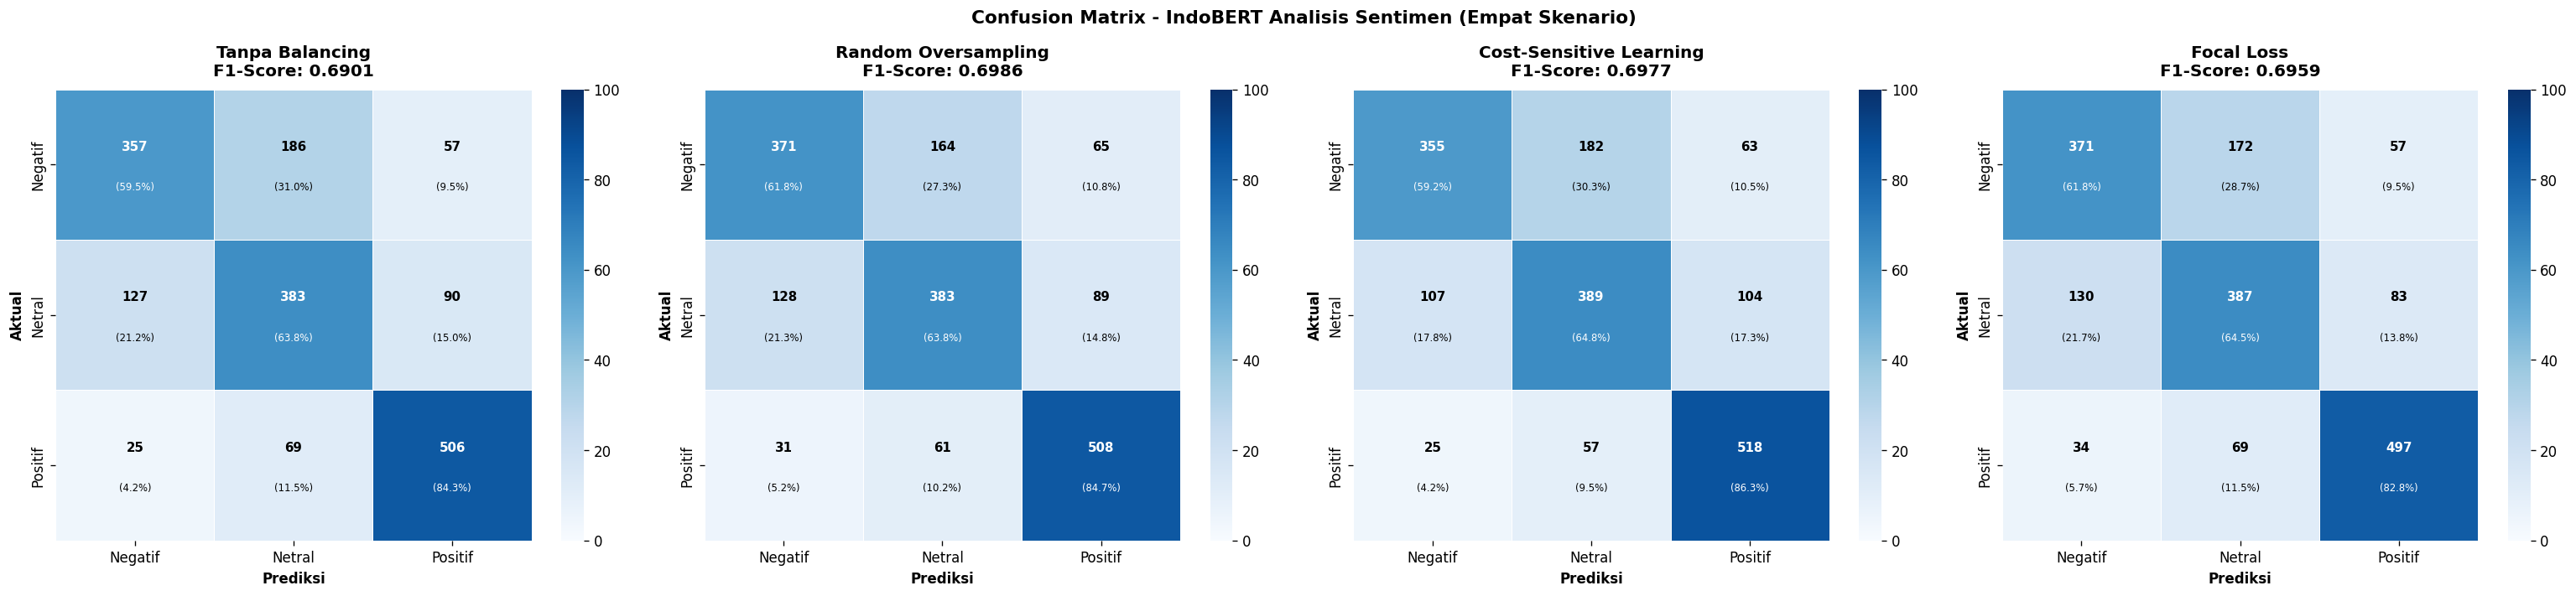

Confusion matrix tersimpan.


In [ ]:
label_names = ['Negatif', 'Netral', 'Positif']

fig, axes = plt.subplots(1, 4, figsize=(26, 6))
fig.suptitle('Confusion Matrix - IndoBERT Analisis Sentimen (Empat Skenario)',
             fontsize=13, fontweight='bold')

cm_data = [
    (preds_nb, true_nb, f1_nb, 'Tanpa Balancing'),
    (preds_wb, true_wb, f1_wb, 'Random Oversampling'),
    (preds_cs, true_cs, f1_cs, 'Cost-Sensitive Learning'),
    (preds_fl, true_fl, f1_fl, 'Focal Loss'),
]

for ax, (preds, true, f1_val, title) in zip(axes, cm_data):
    cm     = confusion_matrix(true, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(
        cm_pct, annot=False, cmap='Blues',
        xticklabels=label_names, yticklabels=label_names,
        linewidths=0.5, linecolor='white',
        ax=ax, vmin=0, vmax=100
    )
    for i in range(3):
        for j in range(3):
            count = cm[i, j]
            pct   = cm_pct[i, j]
            color = 'white' if pct > 55 else 'black'
            ax.text(j + 0.5, i + 0.38, f'{count:,}',
                    ha='center', va='center',
                    fontsize=9, fontweight='bold', color=color)
            ax.text(j + 0.5, i + 0.65, f'({pct:.1f}%)',
                    ha='center', va='center',
                    fontsize=7, color=color)

    ax.set_title(f'{title}\nF1-Score: {f1_val:.4f}', fontweight='bold', pad=10)
    ax.set_xlabel('Prediksi', fontweight='bold')
    ax.set_ylabel('Aktual', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix tersimpan.")

CELL 25 — Classification Report

In [ ]:
for result, nama in [
    (result_no_balance,     'Tanpa Balancing'),
    (result_balanced,       'Random Oversampling'),
    (result_cost_sensitive, 'Cost-Sensitive Learning'),
    (result_focal,          'Focal Loss'),
]:
    print(f"{nama}:")
    print(f"  {'Kelas':<12} {'Precision':>10} {'Recall':>10} {'F1-Score':>10}")
    print(f"  {'-'*45}")
    for cls in ['negatif', 'netral', 'positif']:
        r = result['all_reports'][-1][cls]
        print(f"  {cls:<12} {r['precision']:>10.4f} "
              f"{r['recall']:>10.4f} {r['f1-score']:>10.4f}")
    print()

Tanpa Balancing:
  Kelas         Precision     Recall   F1-Score
  ---------------------------------------------
  negatif          0.7216     0.6133     0.6631
  netral           0.5943     0.6300     0.6117
  positif          0.7737     0.8433     0.8070

Random Oversampling:
  Kelas         Precision     Recall   F1-Score
  ---------------------------------------------
  negatif          0.7262     0.6367     0.6785
  netral           0.6164     0.6533     0.6343
  positif          0.7806     0.8300     0.8045

Cost-Sensitive Learning:
  Kelas         Precision     Recall   F1-Score
  ---------------------------------------------
  negatif          0.6837     0.6700     0.6768
  netral           0.6303     0.5967     0.6130
  positif          0.7764     0.8333     0.8039

Focal Loss:
  Kelas         Precision     Recall   F1-Score
  ---------------------------------------------
  negatif          0.7245     0.6400     0.6796
  netral           0.6226     0.6433     0.6328
  positif 

CELL 26 — Uji Wilcoxon

In [ ]:
f1_nb = result_no_balance['fold_f1s']
f1_wb = result_balanced['fold_f1s']
f1_cs = result_cost_sensitive['fold_f1s']
f1_fl = result_focal['fold_f1s']

pasangan = [
    ('Tanpa Balancing vs Random Oversampling',    f1_nb, f1_wb),
    ('Tanpa Balancing vs Cost-Sensitive',         f1_nb, f1_cs),
    ('Tanpa Balancing vs Focal Loss',             f1_nb, f1_fl),
    ('Random Oversampling vs Cost-Sensitive',     f1_wb, f1_cs),
    ('Random Oversampling vs Focal Loss',         f1_wb, f1_fl),
    ('Cost-Sensitive Learning vs Focal Loss',     f1_cs, f1_fl),
]

print("=" * 70)
print("UJI WILCOXON SIGNED-RANK TEST - SEMUA PASANG PERBANDINGAN")
print("Tingkat signifikansi alpha = 0.05")
print("=" * 70)

alpha = 0.05
for nama, a, b in pasangan:
    stat_w, p_val = wilcoxon(a, b, alternative='two-sided')
    z_score  = abs(stats.norm.ppf(max(p_val / 2, 1e-10)))
    effect_r = z_score / np.sqrt(len(a))

    if effect_r < 0.1:
        efek = "sangat kecil"
    elif effect_r < 0.3:
        efek = "kecil"
    elif effect_r < 0.5:
        efek = "sedang"
    else:
        efek = "besar"

    kesimpulan = "SIGNIFIKAN" if p_val < alpha else "TIDAK SIGNIFIKAN"
    print(f"\n{nama}")
    print(f"  W={stat_w:.4f} | p={p_val:.4f} | r={effect_r:.4f} (efek {efek})")
    print(f"  Kesimpulan: {kesimpulan}")

print("\n" + "=" * 70)

UJI WILCOXON SIGNED-RANK TEST - SEMUA PASANG PERBANDINGAN
Tingkat signifikansi alpha = 0.05

Tanpa Balancing vs Random Oversampling
  W=20.0000 | p=0.4922 | r=0.2172 (efek kecil)
  Kesimpulan: TIDAK SIGNIFIKAN

Tanpa Balancing vs Cost-Sensitive
  W=21.0000 | p=0.5566 | r=0.1859 (efek kecil)
  Kesimpulan: TIDAK SIGNIFIKAN

Tanpa Balancing vs Focal Loss
  W=20.0000 | p=0.4922 | r=0.2172 (efek kecil)
  Kesimpulan: TIDAK SIGNIFIKAN

Random Oversampling vs Cost-Sensitive
  W=26.0000 | p=0.9219 | r=0.0310 (efek sangat kecil)
  Kesimpulan: TIDAK SIGNIFIKAN

Random Oversampling vs Focal Loss
  W=27.0000 | p=1.0000 | r=0.0000 (efek sangat kecil)
  Kesimpulan: TIDAK SIGNIFIKAN

Cost-Sensitive Learning vs Focal Loss
  W=25.0000 | p=0.8457 | r=0.0615 (efek sangat kecil)
  Kesimpulan: TIDAK SIGNIFIKAN



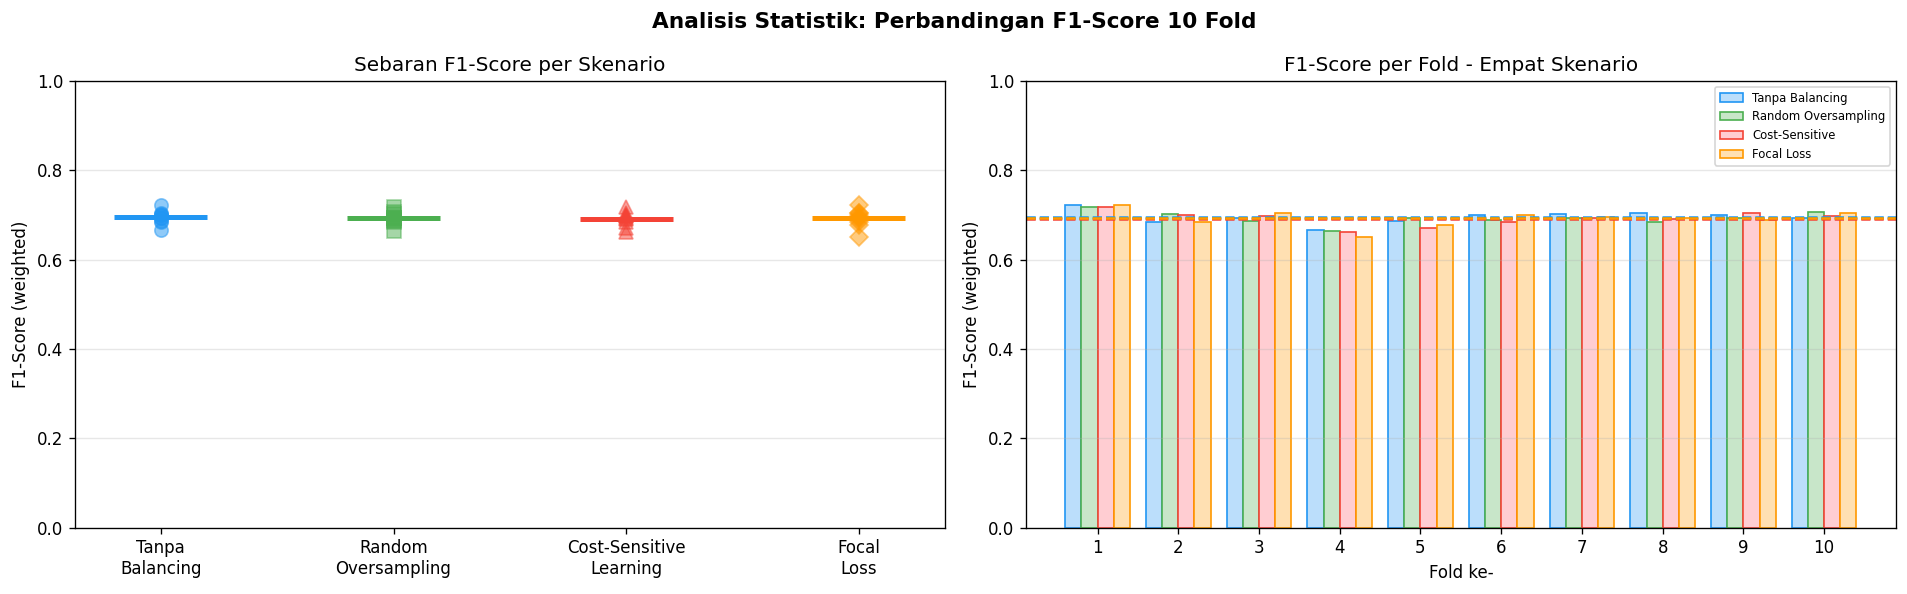

Grafik Wilcoxon tersimpan.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Analisis Statistik: Perbandingan F1-Score 10 Fold',
             fontweight='bold', fontsize=13)

scatter_data = [
    (f1_nb, '#2196F3', 'o', 'Tanpa Balancing'),
    (f1_wb, '#4CAF50', 's', 'Random Oversampling'),
    (f1_cs, '#F44336', '^', 'Cost-Sensitive Learning'),
    (f1_fl, '#FF9800', 'D', 'Focal Loss'),
]

for i, (f1_list, color, marker, label) in enumerate(scatter_data):
    axes[0].plot([i+1]*10, f1_list, marker, color=color,
                 alpha=0.5, markersize=8, label=label)
    axes[0].hlines(np.mean(f1_list), i+0.8, i+1.2, colors=color, linewidth=3)

axes[0].set_xticks([1, 2, 3, 4])
axes[0].set_xticklabels(['Tanpa\nBalancing', 'Random\nOversampling',
                          'Cost-Sensitive\nLearning', 'Focal\nLoss'])
axes[0].set_ylabel('F1-Score (weighted)')
axes[0].set_title('Sebaran F1-Score per Skenario')
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)

x     = np.arange(10)
width = 0.2
axes[1].bar(x - 1.5*width, f1_nb, width, color='#BBDEFB',
            edgecolor='#2196F3', label='Tanpa Balancing')
axes[1].bar(x - 0.5*width, f1_wb, width, color='#C8E6C9',
            edgecolor='#4CAF50', label='Random Oversampling')
axes[1].bar(x + 0.5*width, f1_cs, width, color='#FFCDD2',
            edgecolor='#F44336', label='Cost-Sensitive')
axes[1].bar(x + 1.5*width, f1_fl, width, color='#FFE0B2',
            edgecolor='#FF9800', label='Focal Loss')

for f1_list, color in [(f1_nb, '#2196F3'), (f1_wb, '#4CAF50'),
                        (f1_cs, '#F44336'), (f1_fl, '#FF9800')]:
    axes[1].axhline(np.mean(f1_list), color=color, linestyle='--', linewidth=1.5)

axes[1].set_xlabel('Fold ke-')
axes[1].set_ylabel('F1-Score (weighted)')
axes[1].set_title('F1-Score per Fold - Empat Skenario')
axes[1].set_xticks(x)
axes[1].set_xticklabels([str(i) for i in range(1, 11)])
axes[1].legend(fontsize=7)
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/uji_statistik_wilcoxon.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik Wilcoxon tersimpan.")

CELL 27 — Error Analysis (dengan checkpoint)

In [ ]:
CHECKPOINT_ERR = f'{DRIVE_PATH}/checkpoint_error_analysis.pkl'

if os.path.exists(CHECKPOINT_ERR):
    with open(CHECKPOINT_ERR, 'rb') as f:
        df_eval = pickle.load(f)
    print(f"Checkpoint error analysis ditemukan. {len(df_eval):,} baris.")
else:
    best_tag = max(all_results, key=all_results.get)
    print(f"Skenario terbaik: {best_tag}")

    if best_tag == 'Random Oversampling':
        ea_texts  = texts_balanced
        ea_labels = labels_balanced
        ea_mode   = 'standard'
    elif best_tag == 'Cost-Sensitive Learning':
        ea_texts  = texts_raw
        ea_labels = labels_raw
        ea_mode   = 'weighted'
    elif best_tag == 'Focal Loss':
        ea_texts  = texts_raw
        ea_labels = labels_raw
        ea_mode   = 'focal'
    else:
        ea_texts  = texts_raw
        ea_labels = labels_raw
        ea_mode   = 'standard'

    X_train_ea, X_test_ea, y_train_ea, y_test_ea = train_test_split(
        ea_texts, ea_labels,
        test_size=0.2, stratify=ea_labels, random_state=42
    )

    train_dl_ea = DataLoader(
        ReviewDataset(X_train_ea, y_train_ea, tokenizer, MAX_LEN),
        batch_size=BATCH_SIZE, shuffle=True
    )
    test_dl_ea = DataLoader(
        ReviewDataset(X_test_ea, y_test_ea, tokenizer, MAX_LEN),
        batch_size=BATCH_SIZE
    )

    model_ea = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS
    ).to(device)

    optimizer_ea   = AdamW(model_ea.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps_ea = len(train_dl_ea) * EPOCHS
    scheduler_ea   = get_linear_schedule_with_warmup(
        optimizer_ea,
        num_warmup_steps   = int(0.1 * total_steps_ea),
        num_training_steps = total_steps_ea
    )

    print(f"Training error analysis | {best_tag} | mode: {ea_mode}")
    for epoch in range(EPOCHS):
        if ea_mode == 'weighted':
            loss = train_one_epoch_weighted(
                model_ea, train_dl_ea, optimizer_ea,
                scheduler_ea, device, class_weight_tensor
            )
        elif ea_mode == 'focal':
            loss = train_one_epoch_focal(
                model_ea, train_dl_ea, optimizer_ea,
                scheduler_ea, device,
                gamma=2.0, alpha=focal_alpha_tensor
            )
        else:
            loss = train_one_epoch(
                model_ea, train_dl_ea, optimizer_ea, scheduler_ea, device
            )
        print(f"  Epoch {epoch+1}/{EPOCHS} | Loss: {loss:.4f}")

    f1_ea, acc_ea, preds_ea, true_ea, _ = evaluate(model_ea, test_dl_ea, device)
    print(f"  Selesai | F1: {f1_ea:.4f} | Accuracy: {acc_ea:.4f}")

    del model_ea
    torch.cuda.empty_cache()

    clean_to_orig = dict(zip(
        df_sample['content_clean'].tolist(),
        df_sample['content'].tolist()
    ))

    df_eval = pd.DataFrame({
        'teks_bersih'    : X_test_ea,
        'teks_asli'      : [clean_to_orig.get(t, t) for t in X_test_ea],
        'label_asli'     : [label_map_inv[l] for l in y_test_ea],
        'label_prediksi' : [label_map_inv[p] for p in preds_ea],
        'benar'          : [l == p for l, p in zip(y_test_ea, preds_ea)]
    })

    with open(CHECKPOINT_ERR, 'wb') as f:
        pickle.dump(df_eval, f)
    print("Checkpoint error analysis tersimpan.")

errors = df_eval[~df_eval['benar']].copy()
print(f"\nTotal data test  : {len(df_eval):,}")
print(f"Prediksi benar   : {df_eval['benar'].sum():,} ({df_eval['benar'].mean()*100:.1f}%)")
print(f"Prediksi salah   : {(~df_eval['benar']).sum():,} ({(~df_eval['benar']).mean()*100:.1f}%)")

Skenario terbaik: Tanpa Balancing


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training error analysis | Tanpa Balancing | mode: standard
  Epoch 1/3 | Loss: 0.8230
  Epoch 2/3 | Loss: 0.6293
  Epoch 3/3 | Loss: 0.4590
  Selesai | F1: 0.7009 | Accuracy: 0.7033
Checkpoint error analysis tersimpan.

Total data test  : 1,800
Prediksi benar   : 1,266 (70.3%)
Prediksi salah   : 534 (29.7%)


In [ ]:
error_pattern = (
    errors.groupby(['label_asli', 'label_prediksi'])
          .size()
          .reset_index(name='jumlah')
          .sort_values('jumlah', ascending=False)
)

print("Pola Kesalahan (Aktual -> Diprediksi):")
print("=" * 45)
for _, row in error_pattern.iterrows():
    print(f"  {row['label_asli']:<10} -> {row['label_prediksi']:<10} : {row['jumlah']:>5} kasus")

Pola Kesalahan (Aktual -> Diprediksi):
  negatif    -> netral     :   169 kasus
  netral     -> negatif    :   119 kasus
  netral     -> positif    :    92 kasus
  positif    -> netral     :    68 kasus
  negatif    -> positif    :    64 kasus
  positif    -> negatif    :    22 kasus


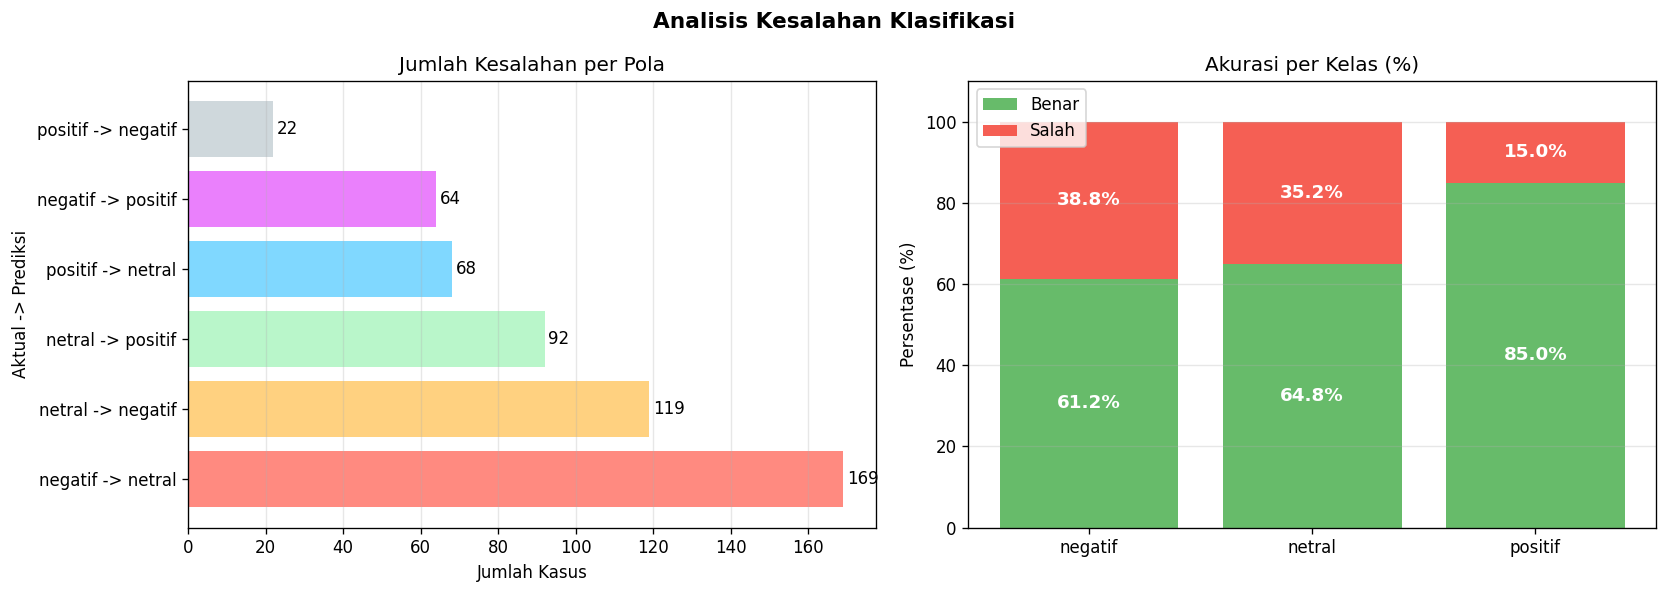

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Analisis Kesalahan Klasifikasi', fontweight='bold', fontsize=13)

colors_err = ['#FF8A80', '#FFD180', '#B9F6CA', '#80D8FF', '#EA80FC', '#CFD8DC']
bars = axes[0].barh(
    [f"{r['label_asli']} -> {r['label_prediksi']}" for _, r in error_pattern.iterrows()],
    error_pattern['jumlah'].values,
    color=colors_err[:len(error_pattern)]
)
for bar, val in zip(bars, error_pattern['jumlah'].values):
    axes[0].text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                 f'{val}', va='center', fontsize=10)
axes[0].set_title('Jumlah Kesalahan per Pola')
axes[0].set_xlabel('Jumlah Kasus')
axes[0].set_ylabel('Aktual -> Prediksi')
axes[0].grid(axis='x', alpha=0.3)

correct_rate = df_eval.groupby('label_asli')['benar'].mean() * 100
wrong_rate   = 100 - correct_rate
x_cls = np.arange(len(correct_rate))
axes[1].bar(x_cls, correct_rate.values, label='Benar', color='#4CAF50', alpha=0.85)
axes[1].bar(x_cls, wrong_rate.values, label='Salah', color='#F44336', alpha=0.85,
            bottom=correct_rate.values)
for i, (cr, wr) in enumerate(zip(correct_rate.values, wrong_rate.values)):
    axes[1].text(i, cr / 2, f'{cr:.1f}%',
                 ha='center', va='center', fontsize=11, fontweight='bold', color='white')
    if wr > 2:
        axes[1].text(i, cr + wr / 2, f'{wr:.1f}%',
                     ha='center', va='center', fontsize=11, fontweight='bold', color='white')
axes[1].set_xticks(x_cls)
axes[1].set_xticklabels(correct_rate.index)
axes[1].set_title('Akurasi per Kelas (%)')
axes[1].set_ylabel('Persentase (%)')
axes[1].set_ylim(0, 110)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{DRIVE_PATH}/error_analysis_chart.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print("=" * 70)
print("CONTOH KALIMAT YANG SALAH DIKLASIFIKASI")
print("=" * 70)
for _, row in error_pattern.iterrows():
    asli   = row['label_asli']
    pred   = row['label_prediksi']
    subset = errors[
        (errors['label_asli'] == asli) &
        (errors['label_prediksi'] == pred)
    ].head(3)
    print(f"\nAktual: {asli.upper()} | Diprediksi: {pred.upper()} ({row['jumlah']} kasus)")
    print("-" * 70)
    for i, (_, r) in enumerate(subset.iterrows(), 1):
        teks = r['teks_asli'] if len(str(r['teks_asli'])) > 10 else r['teks_bersih']
        if len(teks) > 250:
            teks = teks[:250] + "..."
        print(f"  [{i}] {teks}")

print("\n" + "=" * 70)
print("Catatan untuk bagian Pembahasan:")
print("  - Kalimat dengan campuran sentimen positif dan negatif")
print("    cenderung sulit diklasifikasikan dengan tepat.")
print("  - Penggunaan bahasa informal, slang, dan singkatan")
print("    dapat menjadi sumber kesalahan klasifikasi.")
print("  - Kelas netral secara umum paling banyak salah diprediksi,")
print("    ini adalah fenomena umum pada model NLP multi-kelas.")
print("=" * 70)

errors[['teks_asli', 'label_asli', 'label_prediksi']].reset_index(drop=True).to_csv(
    f'{DRIVE_PATH}/error_analysis_detail.csv', index=False
)
print("\nDetail kesalahan tersimpan ke Drive.")

CONTOH KALIMAT YANG SALAH DIKLASIFIKASI

Aktual: NEGATIF | Diprediksi: NETRAL (169 kasus)
----------------------------------------------------------------------
  [1] Membantu Memahami Pelajaran
  [2] saya kemarin sudah berlangganan di ruangguru ruang bljr paket enam bulandan sy juga sudah transfer uang via indomaret dan menggunakan ny selama dua hari tapi pada hari ini aplikadi ruang guru saya terkunci dan kembali seperti semula saat saya blm ber...
  [3] aplikasinya jelek!, jawaban dan soal tidak muncul-muncul

Aktual: NETRAL | Diprediksi: NEGATIF (119 kasus)
----------------------------------------------------------------------
  [1] ksih sya ulasan, sya mau donload ini tpi kok lama bgt ya, udh ke 3 kali nya sya beli pulsa dan setiap sya mau me doanload nya lama betul sush selalu sja ada tulisan mendoanlkad tertunda? klo bisa dibntu plis soal x sya butuh bgt bimbel ini, mau UTS k...
  [2] Maaf aku turunkan bintangnya, aku masih gk paham sama konsep roboguru ... Padahal roboguru itu 

CELL 28 — Ringkasan Final

In [ ]:
output = {
    'model'            : MODEL_NAME,
    'max_len'          : MAX_LEN,
    'batch_size'       : BATCH_SIZE,
    'epochs'           : EPOCHS,
    'learning_rate'    : LEARNING_RATE,
    'sample_per_class' : SAMPLE_PER_CLASS,
    'class_weights'    : class_weights.tolist(),
    'focal_gamma'      : 2.0,
    'tanpa_balancing'  : {
        'avg_f1'   : result_no_balance['avg_f1'],
        'std_f1'   : result_no_balance['std_f1'],
        'avg_acc'  : result_no_balance['avg_acc'],
        'std_acc'  : result_no_balance['std_acc'],
        'fold_f1s' : result_no_balance['fold_f1s'],
    },
    'random_oversampling': {
        'avg_f1'   : result_balanced['avg_f1'],
        'std_f1'   : result_balanced['std_f1'],
        'avg_acc'  : result_balanced['avg_acc'],
        'std_acc'  : result_balanced['std_acc'],
        'fold_f1s' : result_balanced['fold_f1s'],
    },
    'cost_sensitive_learning': {
        'avg_f1'   : result_cost_sensitive['avg_f1'],
        'std_f1'   : result_cost_sensitive['std_f1'],
        'avg_acc'  : result_cost_sensitive['avg_acc'],
        'std_acc'  : result_cost_sensitive['std_acc'],
        'fold_f1s' : result_cost_sensitive['fold_f1s'],
    },
    'focal_loss': {
        'avg_f1'   : result_focal['avg_f1'],
        'std_f1'   : result_focal['std_f1'],
        'avg_acc'  : result_focal['avg_acc'],
        'std_acc'  : result_focal['std_acc'],
        'fold_f1s' : result_focal['fold_f1s'],
    }
}

with open(f'{DRIVE_PATH}/hasil_cv_summary.json', 'w') as f:
    json.dump(output, f, indent=2)

best_name = max(all_results, key=all_results.get)
best_val  = all_results[best_name]

print("=" * 80)
print("TABEL RINGKASAN HASIL PENELITIAN - SIAP MASUK PAPER")
print("=" * 80)
print(f"Model        : IndoBERT-base (indobenchmark/indobert-base-p1)")
print(f"Validasi     : 10-Fold Stratified Cross Validation")
print(f"Metrik utama : F1-Score (weighted)")
print(f"Epoch        : {EPOCHS} | Max Token: {MAX_LEN} | Batch: {BATCH_SIZE}")
print(f"Sampling     : {SAMPLE_PER_CLASS} sampel per kelas (stratified)")
print(f"Focal gamma  : 2.0")
print()
print(f"{'Skenario':<42} {'F1-Score':^20} {'Accuracy':^12}")
print(f"{'-'*42} {'-'*20} {'-'*12}")
print(f"{'(1) IndoBERT Tanpa Balancing':<42} "
      f"{result_no_balance['avg_f1']:.4f} +/- {result_no_balance['std_f1']:.4f}  "
      f"{result_no_balance['avg_acc']:.4f}")
print(f"{'(2) IndoBERT + Random Oversampling':<42} "
      f"{result_balanced['avg_f1']:.4f} +/- {result_balanced['std_f1']:.4f}  "
      f"{result_balanced['avg_acc']:.4f}")
print(f"{'(3) IndoBERT + Cost-Sensitive Learning':<42} "
      f"{result_cost_sensitive['avg_f1']:.4f} +/- {result_cost_sensitive['std_f1']:.4f}  "
      f"{result_cost_sensitive['avg_acc']:.4f}")
print(f"{'(4) IndoBERT + Focal Loss':<42} "
      f"{result_focal['avg_f1']:.4f} +/- {result_focal['std_f1']:.4f}  "
      f"{result_focal['avg_acc']:.4f}")
print(f"{'-'*80}")
print(f"Skenario Terbaik : {best_name}")
print(f"F1-Score Terbaik : {best_val:.4f}")
print("=" * 80)
print()
print("Semua file tersimpan di Drive:")
files = [
    "checkpoint_dataset.pkl",
    "checkpoint_label.pkl",
    "checkpoint_preprocessing.pkl",
    "checkpoint_sample.pkl",
    "checkpoint_cv_tanpa_balancing.pkl",
    "checkpoint_cv_dengan_balancing.pkl",
    "checkpoint_cv_cost_sensitive.pkl",
    "checkpoint_cv_focal_loss.pkl",
    "checkpoint_confusion_matrix.pkl",
    "checkpoint_error_analysis.pkl",
    "dataset_clean.csv",
    "eda_distribusi_label.png",
    "eda_distribusi_rating.png",
    "eda_panjang_teks.png",
    "eda_wordcloud.png",
    "eda_balancing.png",
    "perbandingan_empat_skenario.png",
    "bar_perbandingan_metrik.png",
    "confusion_matrix.png",
    "uji_statistik_wilcoxon.png",
    "error_analysis_chart.png",
    "error_analysis_detail.csv",
    "hasil_cv_summary.json",
]
for nama_file in files:
    print(f"  {DRIVE_PATH}/{nama_file}")

TABEL RINGKASAN HASIL PENELITIAN - SIAP MASUK PAPER
Model        : IndoBERT-base (indobenchmark/indobert-base-p1)
Validasi     : 10-Fold Stratified Cross Validation
Metrik utama : F1-Score (weighted)
Epoch        : 3 | Max Token: 128 | Batch: 16
Sampling     : 3000 sampel per kelas (stratified)
Focal gamma  : 2.0

Skenario                                         F1-Score         Accuracy  
------------------------------------------ -------------------- ------------
(1) IndoBERT Tanpa Balancing               0.6951 +/- 0.0138  0.6970
(2) IndoBERT + Random Oversampling         0.6927 +/- 0.0134  0.6951
(3) IndoBERT + Cost-Sensitive Learning     0.6920 +/- 0.0152  0.6943
(4) IndoBERT + Focal Loss                  0.6922 +/- 0.0183  0.6942
--------------------------------------------------------------------------------
Skenario Terbaik : Tanpa Balancing
F1-Score Terbaik : 0.6951

Semua file tersimpan di Drive:
  /content/drive/MyDrive/Seminar_Nasional_2026_/checkpoint_dataset.pkl
  /conten